In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
resultados = pd.DataFrame({
    "Modelo": [
        "Random Forest + SMOTE",
        "XGBoost + SMOTE",
        "LightGBM + SMOTE"
    ],
    "Accuracy": [
        0.685535,
        0.691824,
        0.691824
    ],
    "Precision": [
        0.486111,
        0.491228,
        0.490196
    ],
    "Recall": [
        0.729167,
        0.583333,
        0.520833
    ],
    "F1-Score": [
        0.583333,
        0.533333,
        0.505051
    ],
    "ROC-AUC": [
        0.717342,
        0.677553,
        0.674925
    ]
})

resultados

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest + SMOTE,0.685535,0.486111,0.729167,0.583333,0.717342
1,XGBoost + SMOTE,0.691824,0.491228,0.583333,0.533333,0.677553
2,LightGBM + SMOTE,0.691824,0.490196,0.520833,0.505051,0.674925


In [3]:
resultados_ordenados = resultados.sort_values(
    by="Recall",
    ascending=False
).reset_index(drop=True)

resultados_ordenados

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest + SMOTE,0.685535,0.486111,0.729167,0.583333,0.717342
1,XGBoost + SMOTE,0.691824,0.491228,0.583333,0.533333,0.677553
2,LightGBM + SMOTE,0.691824,0.490196,0.520833,0.505051,0.674925


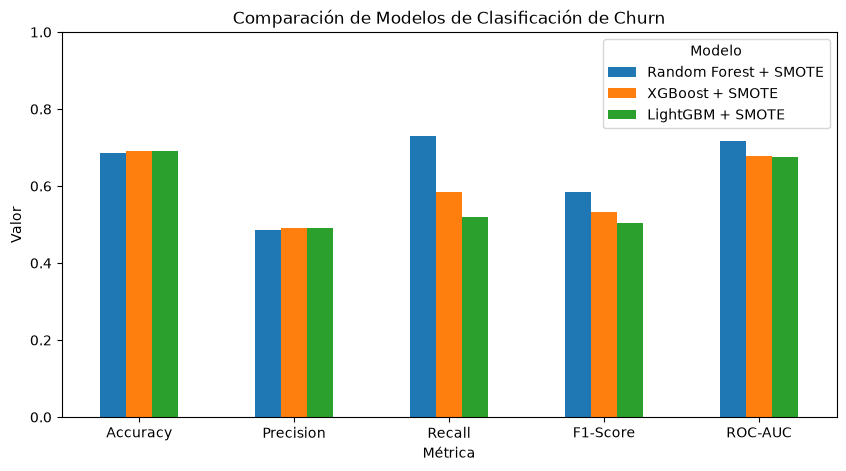

In [4]:
comparacion_plot = resultados.set_index("Modelo").T

comparacion_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylim(0, 1)

plt.title(
    "Comparación de Modelos de Clasificación de Churn"
)

plt.ylabel("Valor")
plt.xlabel("Métrica")

plt.xticks(rotation=0)

plt.legend(
    title="Modelo"
)

plt.show()

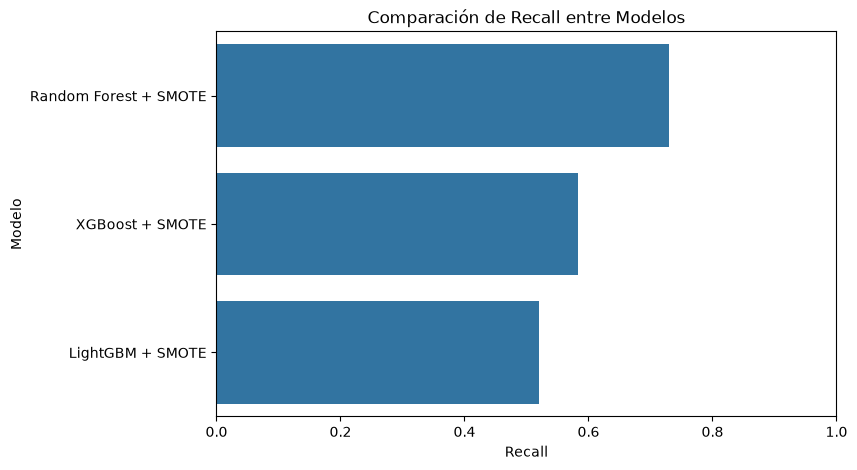

In [5]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=resultados_ordenados,
    x="Recall",
    y="Modelo"
)

plt.xlim(0, 1)

plt.title(
    "Comparación de Recall entre Modelos"
)

plt.xlabel("Recall")
plt.ylabel("Modelo")

plt.show()

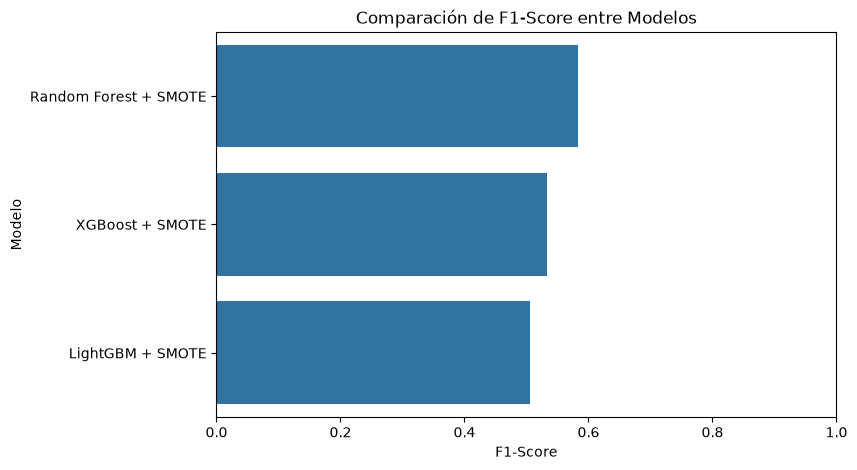

In [6]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=resultados.sort_values(
        by="F1-Score",
        ascending=False
    ),
    x="F1-Score",
    y="Modelo"
)

plt.xlim(0, 1)

plt.title(
    "Comparación de F1-Score entre Modelos"
)

plt.show()

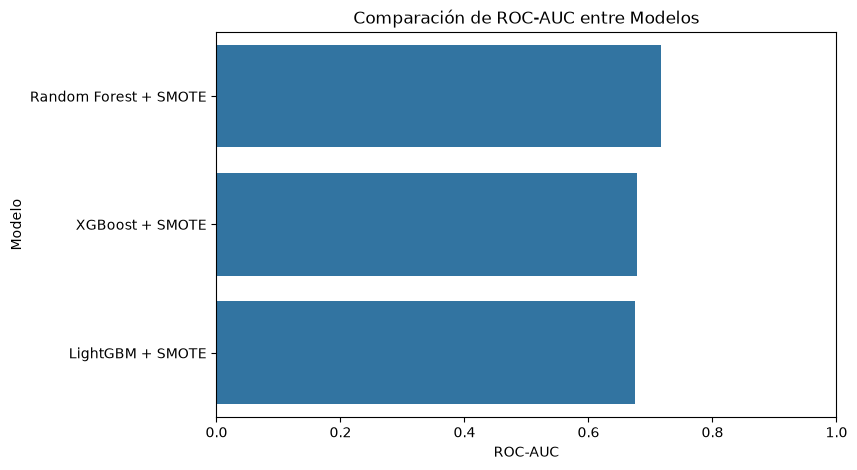

In [7]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=resultados.sort_values(
        by="ROC-AUC",
        ascending=False
    ),
    x="ROC-AUC",
    y="Modelo"
)

plt.xlim(0, 1)

plt.title(
    "Comparación de ROC-AUC entre Modelos"
)

plt.show()

In [8]:
mejor_modelo = resultados.loc[
    resultados["Recall"].idxmax()
]

print("=== MODELO SELECCIONADO ===")
print("Modelo:", mejor_modelo["Modelo"])
print(f"Accuracy:  {mejor_modelo['Accuracy']:.4f}")
print(f"Precision: {mejor_modelo['Precision']:.4f}")
print(f"Recall:    {mejor_modelo['Recall']:.4f}")
print(f"F1-Score:  {mejor_modelo['F1-Score']:.4f}")
print(f"ROC-AUC:   {mejor_modelo['ROC-AUC']:.4f}")

=== MODELO SELECCIONADO ===
Modelo: Random Forest + SMOTE
Accuracy:  0.6855
Precision: 0.4861
Recall:    0.7292
F1-Score:  0.5833
ROC-AUC:   0.7173


In [9]:
rf_recall = resultados.loc[
    resultados["Modelo"] == "Random Forest + SMOTE",
    "Recall"
].iloc[0]

xgb_recall = resultados.loc[
    resultados["Modelo"] == "XGBoost + SMOTE",
    "Recall"
].iloc[0]

lgbm_recall = resultados.loc[
    resultados["Modelo"] == "LightGBM + SMOTE",
    "Recall"
].iloc[0]

print(
    "Diferencia RF vs XGBoost:",
    round(rf_recall - xgb_recall, 4)
)

print(
    "Diferencia RF vs LightGBM:",
    round(rf_recall - lgbm_recall, 4)
)

Diferencia RF vs XGBoost: 0.1458
Diferencia RF vs LightGBM: 0.2083
